# EDA for Datasets in Category A

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

import glob
import os

In [2]:
trip_files = sorted(glob.glob("TripA*.csv"))
df_all_trips = pd.concat((pd.read_csv(f) for f in trip_files), ignore_index=True)

target_cols = [
    'Battery Voltage [V]',
    'Battery Current [A]',
    'Battery Temperature [C]',
    'SoC [%]'
]

In [3]:
# Checking for missing values
missing_values = df_all_trips[target_cols].isnull().sum()
missing_values

Battery Voltage [V]        0
Battery Current [A]        0
Battery Temperature [C]    0
SoC [%]                    0
dtype: int64

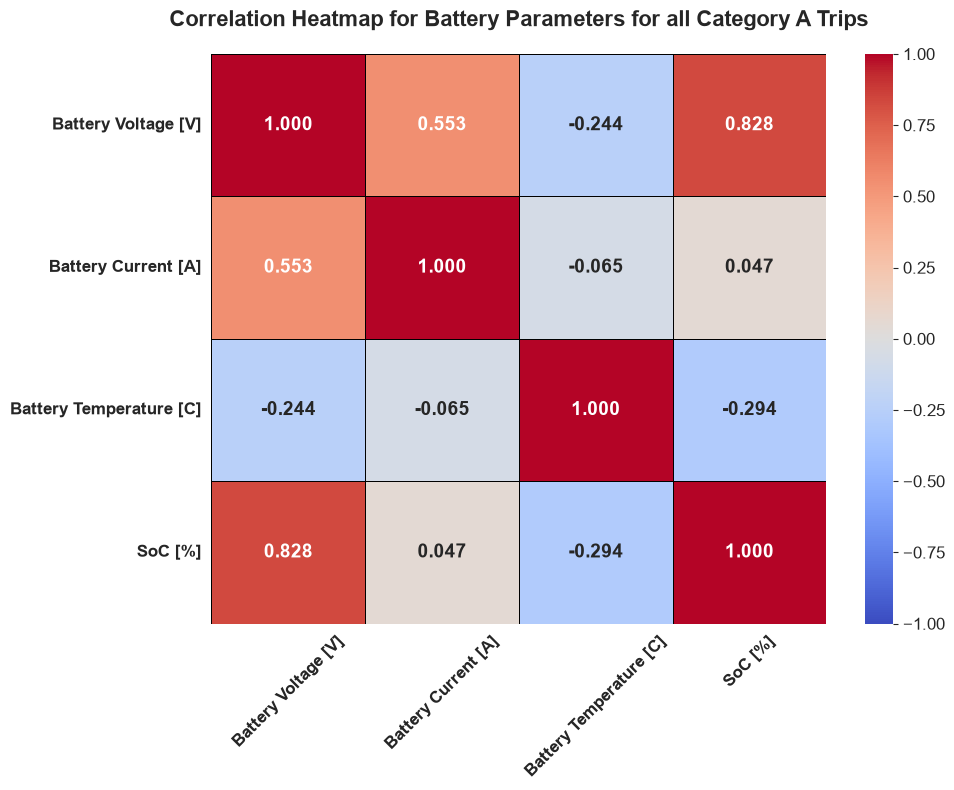

In [4]:
corr_matrix = df_all_trips[target_cols].corr()

plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor='black',
    annot_kws={'size': 14, 'weight': 'bold'}
)

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=12)

plt.title('Correlation Heatmap for Battery Parameters for all Category A Trips', fontsize=16, weight='bold', pad=20)
plt.xticks(fontsize=12, weight='bold', rotation=45, ha='center')
plt.yticks(fontsize=12, weight='bold', rotation=0)
plt.tight_layout()
plt.show()

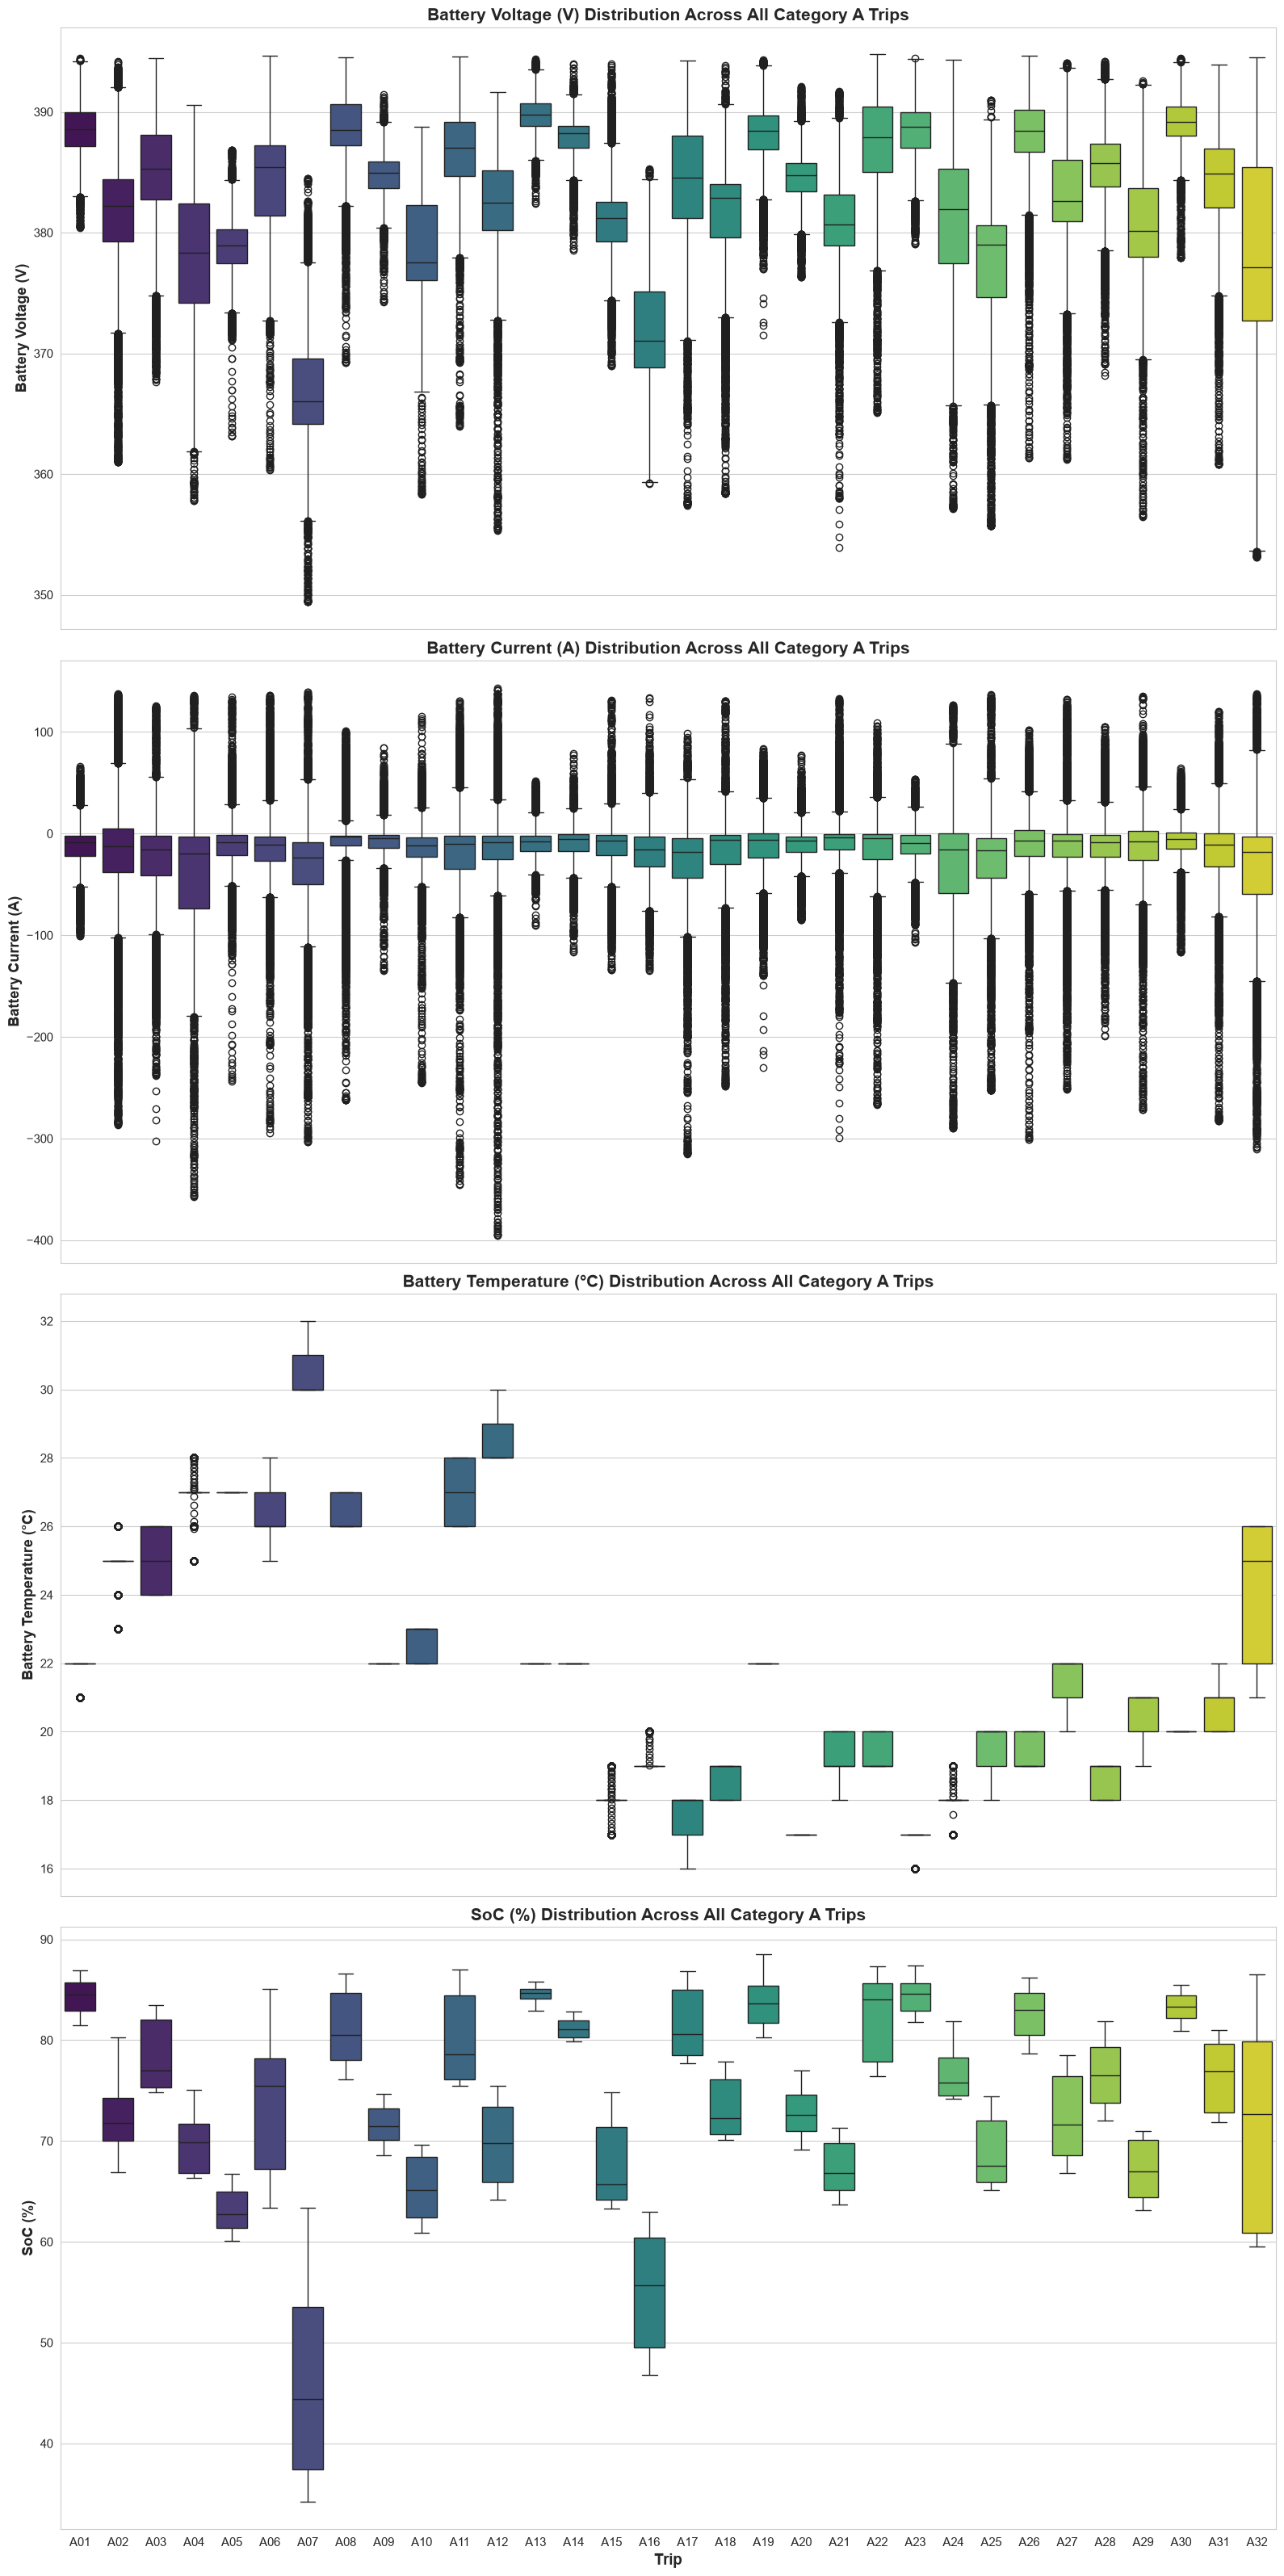

In [5]:
combined_df = pd.concat(
    [pd.read_csv(f).assign(Trip=os.path.splitext(os.path.basename(f))[0].replace('Trip', '')) for f in trip_files],
    ignore_index=True
)

fig, axes = plt.subplots(4, 1, figsize=(16, 32), sharex=True)

plot_specs = [
    ('Battery Voltage [V]', 'Battery Voltage (V) Distribution Across All Category A Trips', 'Battery Voltage (V)'),
    ('Battery Current [A]', 'Battery Current (A) Distribution Across All Category A Trips', 'Battery Current (A)'),
    ('Battery Temperature [C]', 'Battery Temperature (°C) Distribution Across All Category A Trips', 'Battery Temperature (°C)'),
    ('SoC [%]', 'SoC (%) Distribution Across All Category A Trips', 'SoC (%)')
]

for i, (col, title, ylabel) in enumerate(plot_specs):
    sns.boxplot(data=combined_df, x='Trip', y=col, hue='Trip', palette='viridis', legend=False, ax=axes[i])
    axes[i].set_title(title, fontsize=15, weight='bold')
    axes[i].set_ylabel(ylabel, fontsize=13, weight='bold')
    axes[i].tick_params(axis='y', labelsize=11)
    axes[i].set_xlabel('')

axes[-1].set_xlabel('Trip', fontsize=14, weight='bold')
axes[-1].tick_params(axis='x', labelsize=11)

plt.tight_layout()
plt.show()

In [6]:
df1 = pd.read_csv("TripA04.csv")
df2 = pd.read_csv("TripA08.csv")
df3 = pd.read_csv("TripA12.csv")
df4 = pd.read_csv("TripA16.csv")
df5 = pd.read_csv("TripA20.csv")
df6 = pd.read_csv("TripA24.csv")
df7 = pd.read_csv("TripA28.csv")
df8 = pd.read_csv("TripA32.csv")

In [7]:
trip_names = ['TripA04', 'TripA08', 'TripA12', 'TripA16', 'TripA20', 'TripA24', 'TripA28', 'TripA32']

dfs = [pd.read_csv(f"{name}.csv") for name in trip_names]

## SoC versus Time

In [8]:
max_length = max(len(df) for df in [df1, df2, df3, df4, df5, df6, df7, df8])

time_data = []
soc_data = []

for i, df in enumerate([df1, df2, df3, df4, df5, df6, df7, df8]):
    soc = df['SoC [%]']
    time = df['Time [s]'] / 60

    time_data.append(time)
    soc_data.append(soc)

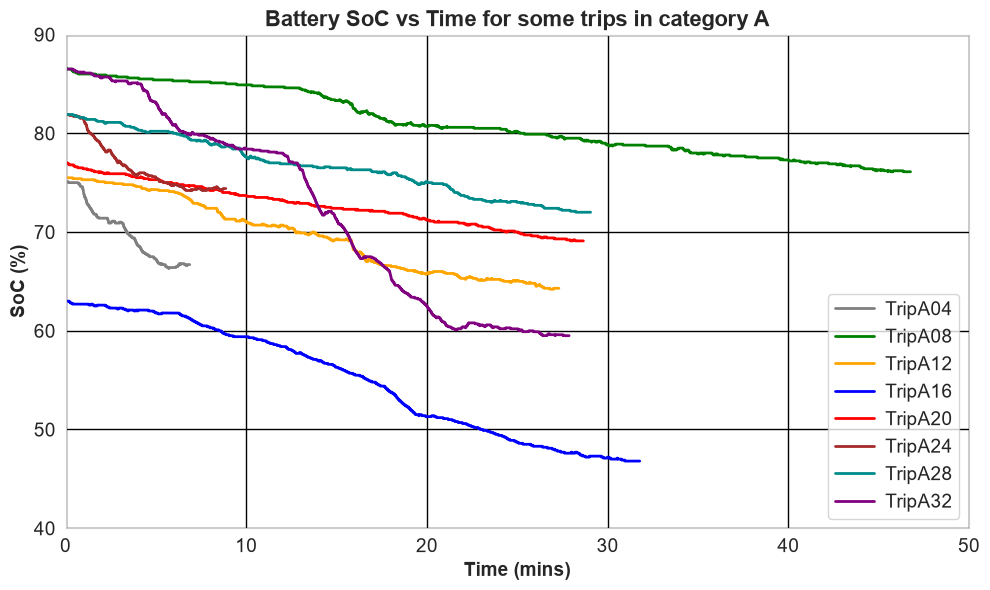

In [9]:
plt.figure(figsize=(10,6))
plt.grid(True, linewidth=1, color='black', alpha=1)
lg = ['TripA04', 'TripA08', 'TripA12', 'TripA16', 'TripA20', 'TripA24', 'TripA28', 'TripA32']
colors = ['grey','green','orange','blue','red','brown','darkcyan','purple']

for i, (time, soc) in enumerate(zip(time_data, soc_data)):
    label = lg[i]
    plt.plot(time, soc, color=colors[i], linewidth=2, label=label)

plt.xlabel('Time (mins)', fontsize=14, weight='bold')
plt.ylabel('SoC (%)', fontsize=14, weight='bold')
plt.ylim((40,90))
plt.xlim((0,50))
plt.tick_params(axis='both', which='major', labelsize=14)
plt.title('Battery SoC vs Time for some trips in category A', fontsize=16, weight='bold')

plt.legend(fontsize=14, ncol=1, loc='lower right', borderpad=0.35, handlelength=2, labelspacing=0.475, handletextpad=0.6)
plt.tight_layout()
plt.show()

In [10]:
print('Summary Statistics for SoC [%] across some trips in category A:')
summary_soc = pd.concat(
    [df['SoC [%]'].describe().round(4) for df in dfs],
    axis=1,
    keys=trip_names
)

summary_soc.loc['var'] = [round(df['SoC [%]'].var(), 4) for df in dfs]
summary_soc = summary_soc.reindex(['count', 'mean', 'std', 'var', 'min', '25%', '50%', '75%', 'max'])

display(summary_soc)

Summary Statistics for SoC [%] across some trips in category A:


,TripA04,TripA08,TripA12,TripA16,TripA20,TripA24,TripA28,TripA32
count,4124.0000,28059.0000,16384.0000,19066.0000,17196.0000,5322.0000,17436.0000,16722.0000
mean,69.9496,80.9590,69.6265,55.0438,72.7392,76.6828,76.6719,72.2256
std,2.8933,3.2512,3.7594,5.5980,2.1911,2.5328,2.9679,9.6616
var,8.3709,10.5706,14.1329,31.3376,4.8010,6.4149,8.8084,93.3471
min,66.3000,76.1000,64.2000,46.8000,69.1000,74.2000,72.0000,59.5000
25%,66.8000,78.0000,65.9000,49.5000,71.0000,74.5000,73.8000,60.9000
50%,69.8350,80.5000,69.8000,55.7000,72.6000,75.8000,76.5000,72.7000
75%,71.6700,84.7000,73.4000,60.4000,74.6000,78.3000,79.3000,79.9000
max,75.1000,86.6000,75.5000,63.0000,77.0000,81.9000,81.9000,86.5000


## Voltage versus Time

In [11]:
max_length = max(len(df) for df in [df1, df2, df3, df4, df5, df6, df7, df8])

time_data = []
voltage_data = []

for i, df in enumerate([df1, df2, df3, df4, df5, df6, df7, df8]):
    voltage = df['Battery Voltage [V]']
    time = df['Time [s]'] / 60

    time_data.append(time)
    voltage_data.append(voltage)

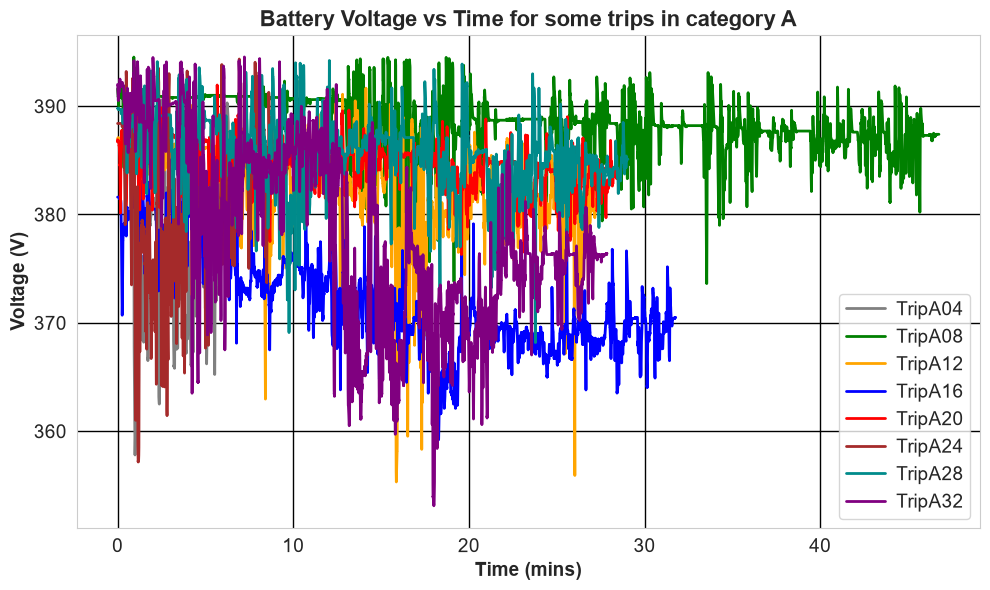

In [12]:
plt.figure(figsize=(10,6))
plt.grid(True, linewidth=1, color='black', alpha=1)
lg = ['TripA04', 'TripA08', 'TripA12', 'TripA16', 'TripA20', 'TripA24', 'TripA28', 'TripA32']
colors = ['grey','green','orange','blue','red','brown','darkcyan','purple']

for i, (time, voltage) in enumerate(zip(time_data, voltage_data)):
    label = lg[i]
    plt.plot(time, voltage, color=colors[i], linewidth=2, label=label)

plt.xlabel('Time (mins)', fontsize=14, weight='bold')
plt.ylabel('Voltage (V)', fontsize=14, weight='bold')
plt.tick_params(axis='both', which='major', labelsize=14)
plt.title('Battery Voltage vs Time for some trips in category A', fontsize=16, weight='bold')

plt.legend(fontsize=14, ncol=1, loc='lower right', borderpad=0.35, handlelength=2, labelspacing=0.475, handletextpad=0.6)
plt.tight_layout()
plt.show()

In [13]:
print('Summary Statistics for Battery Voltage [V] across some trips in category A:')
summary_voltage = pd.concat(
    [df['Battery Voltage [V]'].describe().round(4) for df in dfs],
    axis=1,
    keys=trip_names
)

summary_voltage.loc['var'] = [round(df['Battery Voltage [V]'].var(), 4) for df in dfs]
summary_voltage = summary_voltage.reindex(['count', 'mean', 'std', 'var', 'min', '25%', '50%', '75%', 'max'])

display(summary_voltage)

Summary Statistics for Battery Voltage [V] across some trips in category A:


,TripA04,TripA08,TripA12,TripA16,TripA20,TripA24,TripA28,TripA32
count,4124.0000,28059.0000,16384.0000,19066.0000,17196.0000,5322.0000,17436.0000,16722.0000
mean,377.7679,388.3655,382.2902,372.1806,384.5787,380.9068,385.5036,378.4957
std,6.3936,2.5565,3.9836,4.6034,2.0141,6.4638,3.2690,8.2142
var,40.8776,6.5359,15.8688,21.1914,4.0566,41.7801,10.6862,67.4736
min,357.8000,369.2100,355.3100,359.2000,376.3000,357.1500,368.1760,353.1100
25%,374.1800,387.2600,380.2100,368.8000,383.4000,377.4325,383.8277,372.6925
50%,378.3300,388.5000,382.5000,371.0300,384.7300,381.9600,385.7644,377.1000
75%,382.3825,390.6200,385.1825,375.1300,385.7400,385.2700,387.3821,385.4000
max,390.5900,394.5300,391.6600,385.2900,392.0900,394.3500,394.2135,394.5400


## Current versus Time

In [14]:
max_length = max(len(df) for df in [df1, df2, df3, df4, df5, df6, df7, df8])

time_data = []
current_data = []

for i, df in enumerate([df1, df2, df3, df4, df5, df6, df7, df8]):
    current = df['Battery Current [A]']
    time = df['Time [s]'] / 60

    time_data.append(time)
    current_data.append(current)

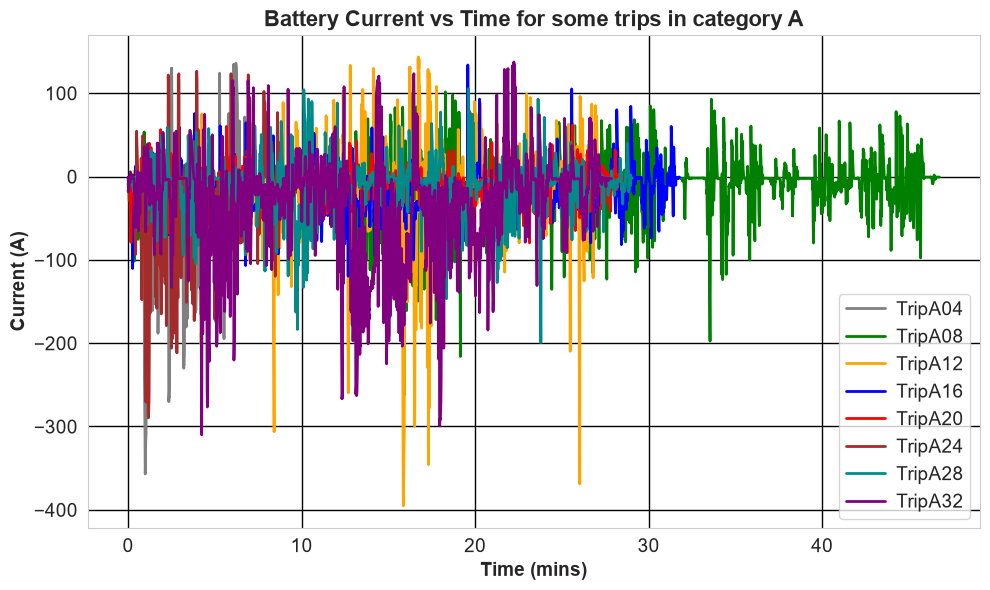

In [15]:
plt.figure(figsize=(10,6))
plt.grid(True, linewidth=1, color='black', alpha=1)
lg = ['TripA04', 'TripA08', 'TripA12', 'TripA16', 'TripA20', 'TripA24', 'TripA28', 'TripA32']
colors = ['grey','green','orange','blue','red','brown','darkcyan','purple']

for i, (time, current) in enumerate(zip(time_data, current_data)):
    label = lg[i]
    plt.plot(time, current, color=colors[i], linewidth=2, label=label)

plt.xlabel('Time (mins)', fontsize=14, weight='bold')
plt.ylabel('Current (A)', fontsize=14, weight='bold')
plt.tick_params(axis='both', which='major', labelsize=14)
plt.title('Battery Current vs Time for some trips in category A', fontsize=16, weight='bold')

plt.legend(fontsize=14, ncol=1, loc='lower right', borderpad=0.35, handlelength=2, labelspacing=0.475, handletextpad=0.6)
plt.tight_layout()
plt.show()

In [16]:
print('Summary Statistics for Battery Current [A] across some trips in category A:')
summary_current = pd.concat(
    [df['Battery Current [A]'].describe().round(4) for df in dfs],
    axis=1,
    keys=trip_names
)

summary_current.loc['var'] = [round(df['Battery Current [A]'].var(), 4) for df in dfs]
summary_current = summary_current.reindex(['count', 'mean', 'std', 'var', 'min', '25%', '50%', '75%', 'max'])

display(summary_current)

Summary Statistics for Battery Current [A] across some trips in category A:


,TripA04,TripA08,TripA12,TripA16,TripA20,TripA24,TripA28,TripA32
count,4124.0000,28059.0000,16384.0000,19066.0000,17196.0000,5322.0000,17436.0000,16722.0000
mean,-45.0568,-8.2505,-15.2048,-18.8512,-10.2091,-31.2080,-12.6515,-35.8678
std,75.3271,29.3413,45.5738,24.0418,17.3914,60.2743,30.0527,61.7473
var,5674.1786,860.9135,2076.9753,578.0060,302.4625,3632.9857,903.1668,3812.7244
min,-357.0200,-262.0600,-395.1800,-135.0900,-84.9400,-289.6000,-199.2709,-310.0400
25%,-73.7050,-11.6500,-25.5125,-32.3000,-18.2225,-58.3525,-23.1101,-59.4875
50%,-19.6450,-3.1000,-8.8200,-15.8900,-6.8500,-15.7150,-8.8076,-17.7700
75%,-2.7000,-1.8500,-1.8900,-3.2600,-2.6000,0.6525,-1.5000,-2.5900
max,136.0100,101.5600,143.5300,133.8800,77.3600,126.4400,105.3121,137.5200


***